# 4. Expected loss

Computes the expected loss $EL = PD \times LGD \times EAD$ of each loan of the test set of the PD model.

**Input:** `data/loan_data.pkl`, `data/pd_test.csv`, `outputs/lgd_ead_models.pickle`.  
**Output:** `outputs/el_by_group.csv` and `outputs/el_by_group.png`, the expected and actual loss by group.

**4.1 Load the data  
4.2 Prepare the inputs  
4.3 LGD and EAD predictions  
&nbsp;&nbsp;&nbsp;&nbsp;4.3.1 LGD  
&nbsp;&nbsp;&nbsp;&nbsp;4.3.2 EAD  
4.4 Expected loss  
4.5 Evaluation  
4.6 Save**

## 4.1 Load the data

We load the loans, the predictions of the PD model on its test set (`PD`, `score`, `default`), and the fitted LGD and EAD models of notebook 03.

In [1]:
import numpy as np
import pandas as pd
import pickle

loan_data = pd.read_pickle('../data/loan_data.pkl')
pd_test = pd.read_csv('../data/pd_test.csv', index_col = 0)

with open('../outputs/lgd_ead_models.pickle', 'rb') as f:
    lgd_ead_models = pickle.load(f)

print(loan_data.shape, pd_test.shape)
print(lgd_ead_models.keys())

(244967, 31) (48994, 3)
dict_keys(['reg_lgd_st_1', 'reg_lgd_st_2', 'reg_lgd_st_3', 'reg_ead', 'continuous_cols', 'categorical_cols', 'kept_states', 'dummy_columns', 'ref_categories'])


## 4.2 Prepare the inputs

The LGD and EAD models were fitted on inputs prepared in notebook 03. We repeat the same preparation for the test loans of the PD model, using only what was learned on the training set of notebook 03: the defaulted loans that are not in the PD test set.

Missing values of `credit_score` and `dti` are filled with the medians of this training set.

In [2]:
# Training set of notebook 03: defaulted loans that are not in the PD test set
train_03 = loan_data[(loan_data['default'] == 1) & (~loan_data.index.isin(pd_test.index))]

print(len(train_03))

medians = {}
for col in ['credit_score', 'dti']:
    medians[col] = train_03[col].median()

print(medians)

11267
{'credit_score': 695.0, 'dti': 40.0}


We keep the inputs of the models for the test loans of the PD model and apply the same preparation as in notebook 03: missing values are filled with the medians, the states that were not kept are merged into `Other`, and `orig_upb` is measured in thousands of dollars.

In [3]:
continuous_cols = lgd_ead_models['continuous_cols']
categorical_cols = lgd_ead_models['categorical_cols']
kept_states = lgd_ead_models['kept_states']

test_loans = loan_data.loc[pd_test.index, continuous_cols + categorical_cols].copy()

for col in ['credit_score', 'dti']:
    test_loans[col] = test_loans[col].fillna(medians[col])

test_loans.loc[~test_loans['property_state'].isin(kept_states), 'property_state'] = 'Other'

test_loans['orig_upb'] = test_loans['orig_upb'] / 1000

print(test_loans.shape)
print(test_loans.isnull().sum())

(48994, 14)
credit_score             0
dti                      0
int_rate                 0
orig_upb                 0
orig_loan_term           0
ltv                      2
mi_pct                   0
occupancy_status         0
loan_purpose             0
channel                  0
property_type            0
num_borrowers           19
first_time_homebuyer     9
property_state           0
dtype: int64


The test loans also have missing values in `ltv` (2 loans) and `num_borrowers` (19 loans). They did not appear in notebook 03, where the training loans were complete. We fill `ltv` with the median and `num_borrowers` with the most frequent value of the training set of notebook 03. The variable `first_time_homebuyer` is not used by any model, so it is not filled.

In [4]:
ltv_median = train_03['ltv'].median()
num_borrowers_mode = train_03['num_borrowers'].mode()[0]

print(ltv_median, num_borrowers_mode)

test_loans['ltv'] = test_loans['ltv'].fillna(ltv_median)
test_loans['num_borrowers'] = test_loans['num_borrowers'].fillna(num_borrowers_mode)

print(test_loans[['ltv', 'num_borrowers']].isnull().sum())

80.0 1.0
ltv              0
num_borrowers    0
dtype: int64


We convert the categorical variables into dummy variables, using exactly the dummy columns of notebook 03: a column missing in the test loans is filled with $0$, and a category that did not exist in the training set of notebook 03 has no column. Then we drop the reference categories.

In [5]:
dummies_test = pd.get_dummies(test_loans[categorical_cols], columns = categorical_cols, prefix_sep = ':', dtype = int)

dummy_columns = lgd_ead_models['dummy_columns']
ref_categories = lgd_ead_models['ref_categories']

# Columns that exist only in the test loans, and columns missing from them
print([col for col in dummies_test.columns if col not in dummy_columns])
print([col for col in dummy_columns if col not in dummies_test.columns])

dummies_test = dummies_test.reindex(columns = dummy_columns, fill_value = 0)

inputs_test = pd.concat([test_loans[continuous_cols], dummies_test], axis = 1)
inputs_test = inputs_test.drop(ref_categories, axis = 1)

print(inputs_test.shape)

[]
[]
(48994, 47)


## 4.3 LGD and EAD predictions

### 4.3.1 LGD

We apply the three LGD models of notebook 03 to the test loans of the PD model, each with its own inputs, and combine them,
$$
\widehat{RR} = \hat p_1 \left[ \hat p_2 + (1 - \hat p_2)\, \hat\mu \right], \qquad \widehat{LGD} = 1 - \widehat{RR}.
$$

In [6]:
import statsmodels.api as sm

reg_lgd_st_1 = lgd_ead_models['reg_lgd_st_1']
reg_lgd_st_2 = lgd_ead_models['reg_lgd_st_2']
reg_lgd_st_3 = lgd_ead_models['reg_lgd_st_3']

X_test = sm.add_constant(inputs_test, has_constant = 'add')

cols_1 = reg_lgd_st_1.model.exog_names
cols_2 = reg_lgd_st_2.model.exog_names
cols_3 = [name for name in reg_lgd_st_3.model.exog_names if name != 'precision']

print(len(cols_1), len(cols_2), len(cols_3))

p_1 = reg_lgd_st_1.predict(X_test[cols_1])
p_2 = reg_lgd_st_2.predict(X_test[cols_2])
mu = reg_lgd_st_3.predict(X_test[cols_3])

rr_hat = p_1 * (p_2 + (1 - p_2) * mu)
lgd_hat = 1 - rr_hat

print(lgd_hat.describe())

46 35 45
count    48994.000000
mean         0.390236
std          0.170598
min          0.003929
25%          0.262745
50%          0.378896
75%          0.505180
max          0.983880
dtype: float64


**Remark.** The predicted LGD lies in $[0, 1]$ and has mean 0.39, lower than the mean actual LGD of the defaulted loans (about 0.51). The models were fitted on defaulted loans only, so applying them to loans that have not defaulted is an extrapolation, which we cannot validate with this data.

### 4.3.2 EAD

We apply the EAD model to the test loans: $\widehat{EAD} = \widehat{CCF} \times \texttt{orig\_upb}$, where `orig_upb` is converted back to dollars.

In [7]:
reg_ead = lgd_ead_models['reg_ead']

cols_ead = reg_ead.model.exog_names
print(len(cols_ead))

ccf_hat = reg_ead.predict(X_test[cols_ead])
ead_hat = ccf_hat * test_loans['orig_upb'] * 1000

print(ccf_hat.describe())
print(ead_hat.describe())

43
count    48994.000000
mean         0.921859
std          0.032294
min          0.800783
25%          0.900788
50%          0.922916
75%          0.943584
max          1.064847
dtype: float64
count     48994.000000
mean     176259.181984
std       98926.586278
min       11243.513091
25%      100360.197646
50%      153679.703633
75%      233534.065301
max      810014.796286
dtype: float64


**Remark.** The predicted CCF lies between 0.80 and 1.06 with mean 0.92, slightly lower than the mean CCF of the defaulted loans (0.95). The predicted EAD has mean 176,259 USD. As for the LGD, the model was fitted on defaulted loans only, so this is an extrapolation to loans that have not defaulted.

## 4.4 Expected loss

For each test loan we compute
$$
EL = PD \times \widehat{LGD} \times \widehat{EAD},
$$
where $PD$ is the prediction of the PD model of notebook 02. All three models were fitted without the test loans of the PD model, so every prediction is out of sample. We summarise the results for the whole portfolio.

In [8]:
# The three predictions must refer to the same loans, in the same order
print((pd_test.index == lgd_hat.index).all(), (pd_test.index == ead_hat.index).all())

el = pd_test['PD'] * lgd_hat * ead_hat

print(el.describe())
print('Total EL:', el.sum())
print('Total EAD:', ead_hat.sum())
print('EL / EAD:', el.sum() / ead_hat.sum())

True True
count     48994.000000
mean       4767.544133
std        8819.065153
min           0.013537
25%         303.262865
50%        1462.161960
75%        5168.049258
max      137857.956618
dtype: float64
Total EL: 233581057.24072802
Total EAD: 8635642362.140463
EL / EAD: 0.02704848666090796


**Remark.** The total expected loss of the 48,994 test loans is about 233.6 million USD, on a total exposure of about 8.64 billion USD, i.e. 2.70% of the exposure. The expected loss per loan is strongly right-skewed: the mean is 4,768 USD and the median 1,462 USD, since most loans have a small PD and a few have a large one.

We plot the distribution of the expected loss of the loans. Since it is strongly right-skewed, we use a logarithmic scale.

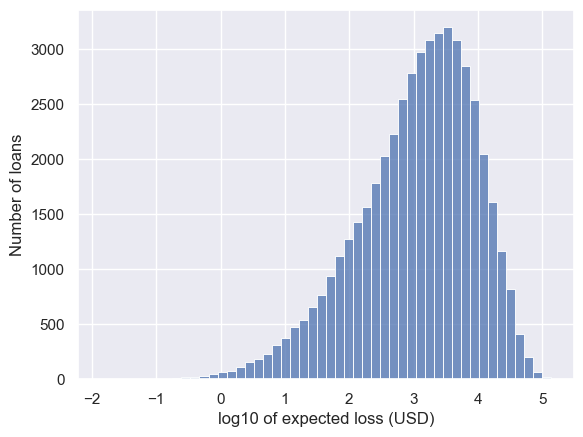

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

sns.histplot(np.log10(el), bins = 50)
plt.xlabel('log10 of expected loss (USD)')
plt.ylabel('Number of loans')
plt.show()

**Remark.** On the logarithmic scale the distribution is unimodal, with a longer tail towards small values. The median, 1,462 USD, corresponds to $\log_{10} \approx 3.2$.

## 4.5 Evaluation

We compare the expected loss with the actual loss of the same 48,994 test loans. The actual loss of a loan that did not default is $0$, and for a defaulted loan it is `actual_loss`. The loss is not reported for 218 of the 2,817 defaulted test loans, so the total actual loss is not known exactly. We do not exclude these loans, because they are all defaulted loans and excluding them would remove defaults from the actual side only. Instead, we compute two values of the total actual loss:

1. a lower bound, where the 218 loans have zero loss,
2. an estimate, where each defaulted loan has the same mean loss as the 2,599 defaulted loans with a reported loss. This is an assumption that we cannot verify.

As the actual loss we use the loss clipped to $[0, EAD]$, consistently with the recovery rate clipped to $[0, 1]$ used to fit the LGD model.

We compute the actual loss of the defaulted test loans: the loss is clipped to $[0, EAD]$, i.e. set to $0$ if it is negative and to the $EAD$ if it is larger.

In [10]:
test_defaults = loan_data.loc[pd_test.index]
test_defaults = test_defaults[test_defaults['default'] == 1]

print(len(test_defaults), test_defaults['actual_loss'].isnull().sum())

known = test_defaults[test_defaults['actual_loss'].notnull()]

ead_actual = known['zero_balance_removal_upb']
loss_raw = known['actual_loss']
loss_clipped = np.minimum(np.maximum(loss_raw, 0), ead_actual)

print(loss_raw.sum(), loss_clipped.sum())

2817 218
228615592.15000004 225060155.39000002


In [11]:
actual_lower = loss_clipped.sum()
actual_estimate = loss_clipped.sum() * len(test_defaults) / len(known)

print('Expected loss:', el.sum())
print('Actual loss, lower bound:', actual_lower)
print('Actual loss, estimate:', actual_estimate)
print('Expected / actual (lower bound):', el.sum() / actual_lower)
print('Expected / actual (estimate):', el.sum() / actual_estimate)

# Expected and actual number of defaults on all test loans
print('Expected defaults:', pd_test['PD'].sum())
print('Actual defaults:', pd_test['default'].sum())

Expected loss: 233581057.24072802
Actual loss, lower bound: 225060155.39000002
Actual loss, estimate: 243937844.45310888
Expected / actual (lower bound): 1.0378605525974263
Expected / actual (estimate): 0.9575433355345087
Expected defaults: 2838.42818996153
Actual defaults: 2817


**Remark.** The expected loss of the portfolio (233.6 million USD) lies within 4% of the actual loss in the whole range of values: the ratio is 1.04 if the 218 loans with unknown loss had zero loss, and 0.96 under the assumption that they have the mean loss of the other defaulted loans. The expected number of defaults (2,838) is close to the actual one (2,817). So the total expected loss is estimated well, up to the uncertainty caused by the missing losses.

We sort the loans by expected loss, split them into 10 groups of equal size, and compare in each group the total expected loss with the total actual loss. For the actual loss we use the lower bound, i.e. the loans with unknown loss count as zero.

         expected      actual
group                        
0        0.114123    0.126234
1        0.572218    0.846016
2        1.507430    1.426277
3        3.107646    2.638737
4        5.543613    4.775498
5        9.370190    9.082003
6       15.462760   14.203801
7       25.713940   21.661635
8       45.861275   40.892744
9      126.327862  129.407210


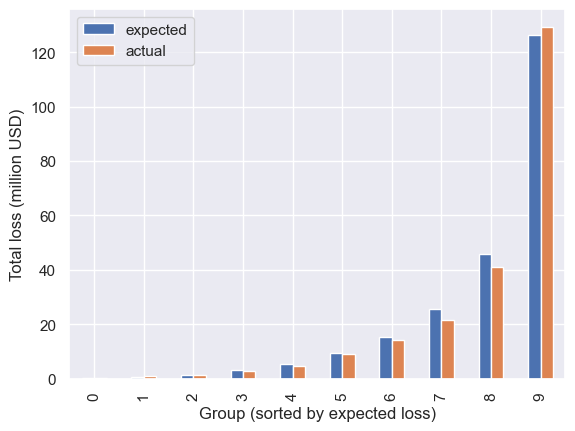

In [12]:
# Actual (clipped) loss of every test loan: 0 for the loans without a known loss
actual_loss_all = pd.Series(0.0, index = pd_test.index)
actual_loss_all.loc[known.index] = loss_clipped

groups = pd.DataFrame({'expected': el, 'actual': actual_loss_all})
groups['group'] = pd.qcut(groups['expected'], 10, labels = False)

table = groups.groupby('group')[['expected', 'actual']].sum() / 1000000
print(table)

table.plot(kind = 'bar')
plt.xlabel('Group (sorted by expected loss)')
plt.ylabel('Total loss (million USD)')
plt.show()

**Remark.** The expected loss increases together with the actual loss from group to group, so the model ranks the loans correctly. The top group contains 54% of the total expected loss, and there the expected loss is within 3% of the actual one (ratio 0.98). In the groups 2 to 8 the expected loss is between 3% and 19% above the actual one, but the actual loss is a lower bound, since the 218 loans with unknown loss count as zero, and we cannot tell how much of the difference is due to this. The groups 0 and 1 hold less than 0.3% of the total expected loss, so their ratios are not informative.

## 4.6 Save

We save the expected and actual loss by group as a table and a figure. We do not save loan-level results.

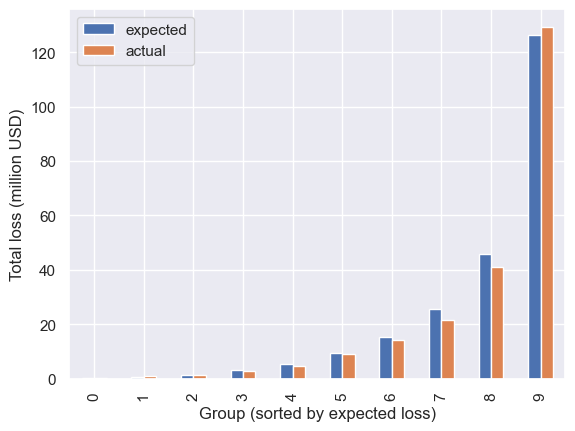

In [13]:
table.to_csv('../outputs/el_by_group.csv')

table.plot(kind = 'bar')
plt.xlabel('Group (sorted by expected loss)')
plt.ylabel('Total loss (million USD)')
plt.savefig('../outputs/el_by_group.png', bbox_inches = 'tight')
plt.show()